# Which Products Earn Their Place, and Where Do Shoppers Drop Out? Product and Funnel Analysis

**Author:** Pham Hong Hieu (Haven) · **Data:** an online stuffed-toy retailer, March 2012 to March 2015: 40,025 order items,
1,731 refunds, 472,871 sessions and 1,188,124 page views

## The brief

Management wants to know which products drive the business and where each product's purchase funnel leaks:

1. **Product performance.** Which products generate the most revenue after refunds, and which have quality or
   return problems?
2. **Funnel diagnosis.** From the product catalogue to the order confirmation, where do shoppers drop out for each
   product?
3. **Early purchase signals.** Can a session's purchase likelihood be estimated when the visitor arrives, so that
   traffic can be valued before it converts?

## 1. Setup and data loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.titleweight": "bold", "figure.dpi": 110})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path("../data")
FIG_DIR = Path("../reports/figures")
TABLE_DIR = Path("../reports/tables")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
items = pd.read_csv(DATA_DIR / "order_items.csv", parse_dates=["created_at"])
refunds = pd.read_csv(DATA_DIR / "order_item_refunds.csv")
products = pd.read_csv(DATA_DIR / "products.csv", parse_dates=["created_at"])
sessions = pd.read_csv(DATA_DIR / "website_sessions.csv.gz", parse_dates=["created_at"])
pageviews = pd.read_csv(DATA_DIR / "website_pageviews.csv.gz", parse_dates=["created_at"])
for name, table in [("order items", items), ("refunds", refunds), ("products", products),
                    ("sessions", sessions), ("page views", pageviews)]:
    print(f"{name:<12} {len(table):>10,} rows")
products

order items      40,025 rows
refunds           1,731 rows
products              4 rows
sessions        472,871 rows
page views    1,188,124 rows


,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda
3,4,2014-02-05 10:00:00,The Hudson River Mini bear


The four products launched at different times. That matters for any comparison: before January 2013 nobody could
view or buy the Love Bear.

## 2. Product performance: revenue and refunds

- **Gross revenue:** sum of item prices.
- **Refund rate:** share of items sold that were refunded.
- **Net revenue:** gross revenue minus refunds.

In [3]:
detail = (items.merge(products[["product_id", "product_name"]], on="product_id", how="left", validate="many_to_one")
               .merge(refunds[["order_item_id", "refund_amount_usd"]], on="order_item_id", how="left", validate="one_to_one"))
detail["refund_amount_usd"] = detail["refund_amount_usd"].fillna(0)
detail["refunded"] = detail["refund_amount_usd"] > 0
detail["gross_margin"] = detail["price_usd"] - detail["cogs_usd"]

performance = (detail.groupby("product_name")
               .agg(items_sold=("order_item_id", "count"), gross_revenue=("price_usd", "sum"),
                    refunds=("refund_amount_usd", "sum"), refunded_items=("refunded", "sum"),
                    gross_margin=("gross_margin", "sum"))
               .assign(net_revenue=lambda d: d["gross_revenue"] - d["refunds"],
                       refund_rate_pct=lambda d: d["refunded_items"] / d["items_sold"] * 100,
                       margin_pct=lambda d: d["gross_margin"] / d["gross_revenue"] * 100)
               .sort_values("net_revenue", ascending=False))
performance["net_revenue_share_pct"] = performance["net_revenue"] / performance["net_revenue"].sum() * 100
performance.to_csv(TABLE_DIR / "product_performance.csv")
performance

,items_sold,gross_revenue,refunds,refunded_items,gross_margin,net_revenue,refund_rate_pct,margin_pct,net_revenue_share_pct
product_name,,,,,,,,,
The Original Mr. Fuzzy,24226,"1,211,057.74","61,837.63",1237,"738,893.00","1,149,220.11",5.11,61.01,62.01
The Forever Love Bear,5796,"347,702.04","7,738.71",129,"217,350.00","339,963.33",2.23,62.51,18.34
The Birthday Sugar Panda,4985,"229,260.15","13,842.99",301,"157,027.50","215,417.16",6.04,68.49,11.62
The Hudson River Mini bear,5018,"150,489.82","1,919.36",64,"102,869.00","148,570.46",1.28,68.36,8.02


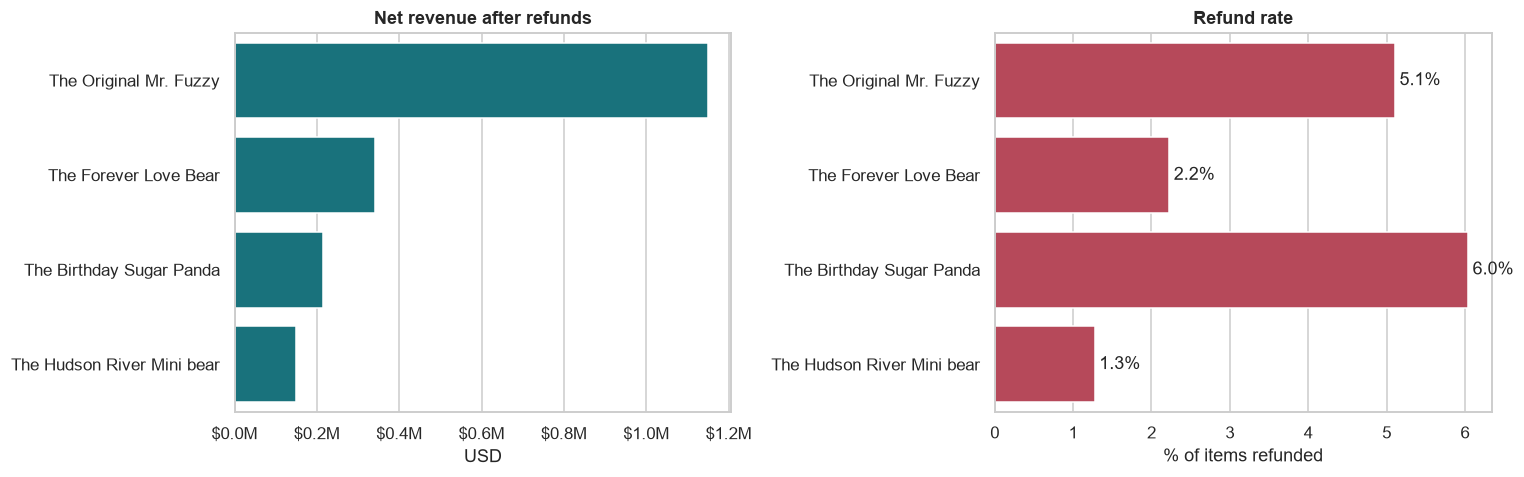

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = performance.index
sns.barplot(x=performance["net_revenue"], y=order, color="#087F8C", ax=axes[0])
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v / 1e6:.1f}M"))
axes[0].set(title="Net revenue after refunds", xlabel="USD", ylabel="")
sns.barplot(x=performance["refund_rate_pct"], y=order, color="#C8374D", ax=axes[1])
axes[1].set(title="Refund rate", xlabel="% of items refunded", ylabel="")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="{:.1f}%", padding=3)
fig.tight_layout()
save(fig, "01_product_performance")
plt.show()

**The Original Mr. Fuzzy** is the core of the business, with 62% of net revenue, although it has also been on sale
for up to two years longer than the others. **The Birthday Sugar Panda** has the highest refund rate (6.0%), and
Mr. Fuzzy is close behind (5.1%). The Love Bear and Mini Bear stay near 1–2%. For the flagship product, that level
of returns is worth a quality and product-page review.

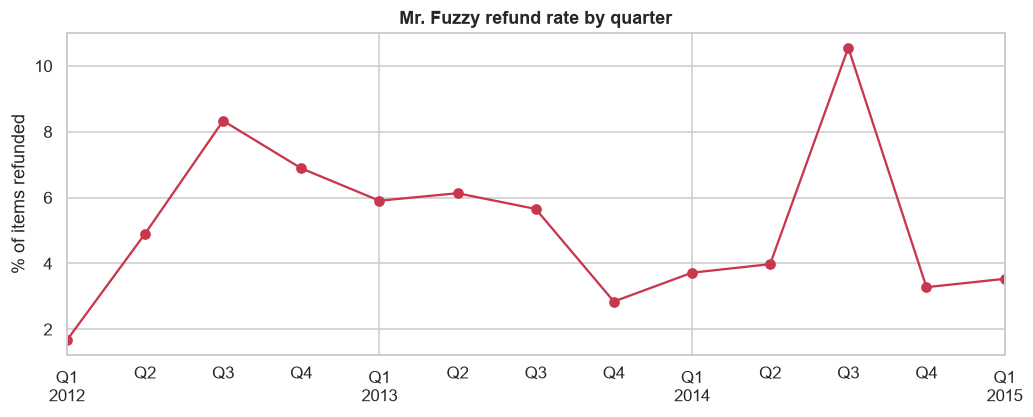

quarter,2012Q1,2012Q2,2012Q3,2012Q4,2013Q1,2013Q2,2013Q3,2013Q4,2014Q1,2014Q2,2014Q3,2014Q4,2015Q1
refund_rate_pct,1.70,4.90,8.30,6.90,5.90,6.10,5.70,2.80,3.70,4.00,10.60,3.30,3.50


In [5]:
refunds_by_quarter = (detail.assign(quarter=detail["created_at"].dt.to_period("Q"))
                      .query("product_name == 'The Original Mr. Fuzzy'")
                      .groupby("quarter")["refunded"].mean() * 100)
fig, ax = plt.subplots(figsize=(11, 3.8))
refunds_by_quarter.plot(ax=ax, marker="o", color="#C8374D")
ax.set(title="Mr. Fuzzy refund rate by quarter", xlabel="", ylabel="% of items refunded")
save(fig, "02_fuzzy_refund_trend")
plt.show()
refunds_by_quarter.round(1).to_frame("refund_rate_pct").T

Mr. Fuzzy's refund rate is not stable. It moves sharply from quarter to quarter, which points to specific events such
as supplier or batch problems, not a constant level of dissatisfaction. Refund dates and reasons by supplier lot
would be the next data to request.

## 3. Funnel diagnosis by product

To compare products fairly, the funnel uses only sessions **from 5 February 2014**, when all four products were on
sale. A session counts at a step only if it also reached every earlier step:

`/products` → product page → `/cart` → `/shipping` → `/billing` → `/thank-you-for-your-order`

In [6]:
PRODUCT_PAGES = {
    "The Original Mr. Fuzzy": "/the-original-mr-fuzzy",
    "The Forever Love Bear": "/the-forever-love-bear",
    "The Birthday Sugar Panda": "/the-birthday-sugar-panda",
    "The Hudson River Mini bear": "/the-hudson-river-mini-bear",
}
STEPS = ["Catalogue", "Product page", "Cart", "Shipping", "Billing", "Order placed"]
start = products["created_at"].max()

window = pageviews[pageviews["created_at"] >= start].copy()
window["page"] = window["pageview_url"].replace({"/billing-2": "/billing"})
flags = (window.assign(seen=1)
         .pivot_table(index="website_session_id", columns="page", values="seen", aggfunc="max", fill_value=0))

rows = []
for product, url in PRODUCT_PAGES.items():
    reached = flags["/products"] == 1
    counts = [int(reached.sum())]
    for page in [url, "/cart", "/shipping", "/billing", "/thank-you-for-your-order"]:
        reached &= flags[page] == 1
        counts.append(int(reached.sum()))
    rows.append(pd.Series(counts, index=STEPS, name=product))
funnel = pd.DataFrame(rows)
step_rates = funnel.div(funnel.shift(axis=1)).iloc[:, 1:] * 100
step_rates.columns = [f"{a} -> {b}" for a, b in zip(STEPS[:-1], STEPS[1:])]

print(f"Sessions from {start.date()} that reached the catalogue: {funnel.iloc[0, 0]:,}")
funnel.to_csv(TABLE_DIR / "funnel_counts.csv")
display(funnel)
step_rates.round(1)

Sessions from 2014-02-05 that reached the catalogue: 160,503


,Catalogue,Product page,Cart,Shipping,Billing,Order placed
The Original Mr. Fuzzy,160503,95149,40774,27698,22379,14344
The Forever Love Bear,160503,18585,10371,6946,5525,3424
The Birthday Sugar Panda,160503,17560,8123,5533,4430,2817
The Hudson River Mini bear,160503,2610,1700,1148,918,581


,Catalogue -> Product page,Product page -> Cart,Cart -> Shipping,Shipping -> Billing,Billing -> Order placed
The Original Mr. Fuzzy,59.30,42.90,67.90,80.80,64.10
The Forever Love Bear,11.60,55.80,67.00,79.50,62.00
The Birthday Sugar Panda,10.90,46.30,68.10,80.10,63.60
The Hudson River Mini bear,1.60,65.10,67.50,80.00,63.30


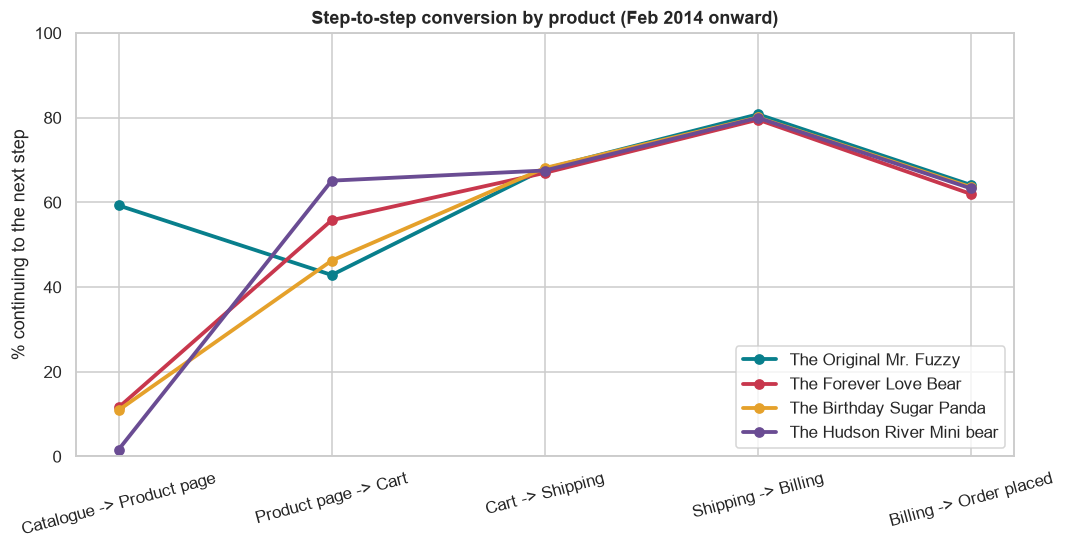

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
colours = ["#087F8C", "#C8374D", "#E5A12B", "#6A4C93"]
for (product, rates), colour in zip(step_rates.iterrows(), colours):
    ax.plot(rates.index, rates.values, marker="o", linewidth=2.5, color=colour, label=product)
ax.set(title="Step-to-step conversion by product (Feb 2014 onward)", ylabel="% continuing to the next step", ylim=(0, 100))
ax.tick_params(axis="x", rotation=15)
ax.legend(loc="lower right")
save(fig, "03_step_conversion")
plt.show()

Three patterns stand out:

- **Catalogue → product page is where products separate.** 59% of catalogue visitors open Mr. Fuzzy, against about
  11–12% for the Love Bear and Sugar Panda. The Mini Bear is the extreme case (under 2%). It is sold as a low-priced
  add-on, so very few visitors go to its page directly.
- **Product page → cart favours the newer products.** Visitors who open the Love Bear page add it to the cart 56% of
  the time, against 43% for Mr. Fuzzy. Interest is the Love Bear's bottleneck, not its product page.
- **Checkout is product-neutral.** From cart onward, conversion is 62–68%, 80% and 62–64% at each step for every
  product. The checkout pages work the same way regardless of what is in the cart.

### Was the Love Bear's low click-through just a timing effect?

A naive analysis over the full three years includes the ten months before the Love Bear existed. That could make
its catalogue click-through look lower than it really is. The check below compares the naive figure with fair
windows.

In [8]:
all_flags = (pageviews.assign(seen=1)
             .pivot_table(index="website_session_id", columns="pageview_url", values="seen", aggfunc="max", fill_value=0))
catalogue = all_flags["/products"] == 1
naive = (all_flags.loc[catalogue, "/the-forever-love-bear"].mean() * 100)
since_launch = all_flags.loc[catalogue & (all_flags.index.isin(
    pageviews.loc[pageviews["created_at"] >= products.loc[1, "created_at"], "website_session_id"])),
    "/the-forever-love-bear"].mean() * 100
fair = step_rates.loc["The Forever Love Bear"].iloc[0]
pd.Series({
    "Full period, 2012-2015 (naive)": naive,
    "Since Love Bear launch, Jan 2013": since_launch,
    "All four products on sale, Feb 2014": fair,
}, name="catalogue -> Love Bear page (%)").round(1).to_frame()

,catalogue -> Love Bear page (%)
"Full period, 2012-2015 (naive)",10.00
"Since Love Bear launch, Jan 2013",11.30
"All four products on sale, Feb 2014",11.60


The timing effect is small. The click-through rises only from 10.0% to 11.6% when the window is fair. The Love Bear's
weak pull at the catalogue is a real finding, not a measurement artefact, and it confirms that visibility is the
product's main bottleneck.

## 4. Early purchase signals

A purchase-prediction model is only useful if it relies on information available **before** the outcome. Page
counts and visits to the cart or billing pages happen on the way to an order, so a model using them would predict
purchases it has already effectively seen. The model below uses only what is known when the visitor **lands**:
traffic source, campaign, device, whether it is a repeat visit, and the landing page.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

landing = (pageviews.sort_values("website_pageview_id").groupby("website_session_id")["pageview_url"]
           .first().rename("landing_page"))
converted = pageviews.groupby("website_session_id")["pageview_url"].apply(
    lambda s: int("/thank-you-for-your-order" in set(s))).rename("converted")
model_df = (sessions.set_index("website_session_id")
            .join(landing).join(converted)
            .assign(utm_source=lambda d: d["utm_source"].fillna("none"),
                    utm_campaign=lambda d: d["utm_campaign"].fillna("none"),
                    referred=lambda d: d["http_referer"].notna().astype(int)))
features = ["utm_source", "utm_campaign", "device_type", "landing_page", "is_repeat_session", "referred"]
X = pd.get_dummies(model_df[features], columns=["utm_source", "utm_campaign", "device_type", "landing_page"], dtype=int)
y = model_df["converted"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=50, class_weight="balanced",
                               random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
print(f"Sessions: {len(model_df):,} | conversion rate: {y.mean():.2%}")
print(f"ROC-AUC on held-out sessions: {auc:.3f}")

Sessions: 472,871 | conversion rate: 6.83%
ROC-AUC on held-out sessions: 0.629


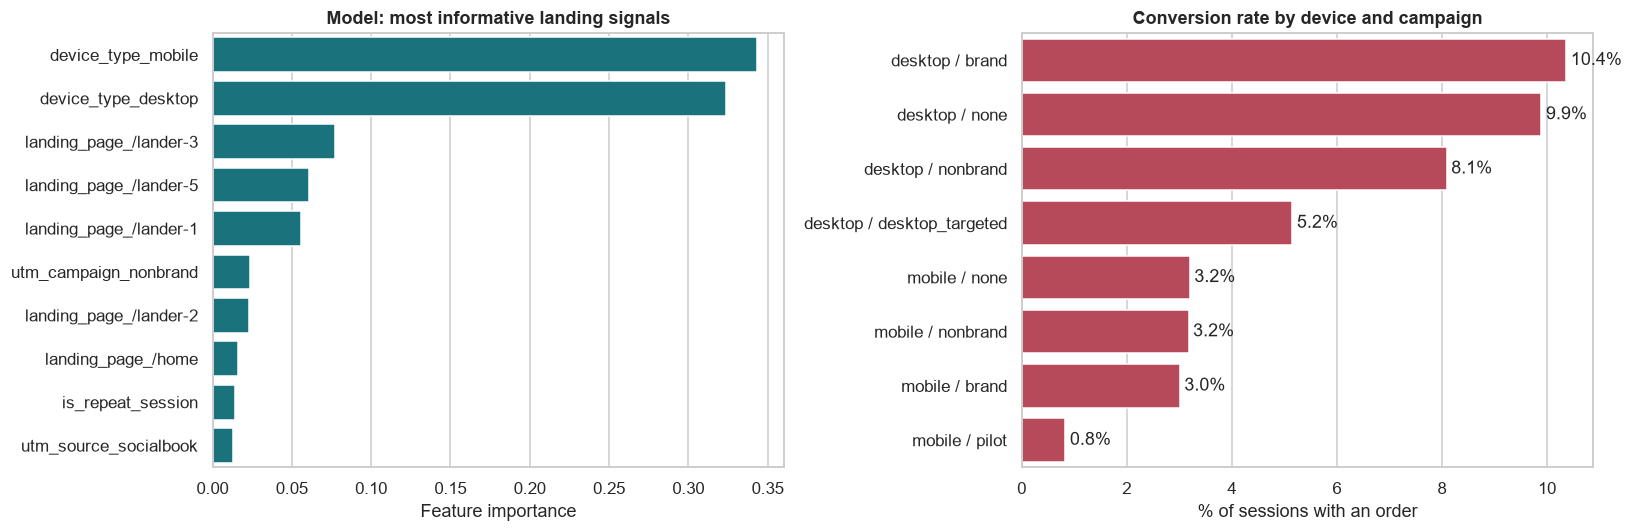

sessions  conversion_pct
device_type utm_campaign                              
desktop     brand                26789           10.37
            none                 51576            9.89
            nonbrand            242550            8.09
            desktop_targeted      5590            5.15
mobile      none                 31752            3.20
            nonbrand             95065            3.18
            brand                14454            3.01
            pilot                 4573            0.83

In [10]:
segment_rates = (model_df.groupby(["device_type", "utm_campaign"])["converted"]
                 .agg(sessions="count", conversion_pct="mean")
                 .assign(conversion_pct=lambda d: d["conversion_pct"] * 100)
                 .query("sessions >= 1000").sort_values("conversion_pct", ascending=False))
segment_rates.to_csv(TABLE_DIR / "conversion_by_device_campaign.csv")

importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=importance.values, y=importance.index, color="#087F8C", ax=axes[0])
axes[0].set(title="Model: most informative landing signals", xlabel="Feature importance", ylabel="")
plot_rates = segment_rates.reset_index()
plot_rates["segment"] = plot_rates["device_type"] + " / " + plot_rates["utm_campaign"]
sns.barplot(data=plot_rates, x="conversion_pct", y="segment", color="#C8374D", ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="{:.1f}%", padding=3)
axes[1].set(title="Conversion rate by device and campaign", xlabel="% of sessions with an order", ylabel="")
fig.tight_layout()
save(fig, "04_landing_signals")
plt.show()
segment_rates

With only landing information, the model reaches a ROC-AUC of about 0.63. That is a modest but realistic result,
unlike the near-perfect scores of a model that sees cart and billing visits. Its value is in ranking traffic, and the
dominant signal is **device**. Desktop sessions convert at 8–10% whatever the campaign, mobile sessions at about 3%,
and the mobile pilot campaign at under 1%. On desktop, brand searches convert somewhat better than non-brand (10.4%
vs 8.1%). On mobile the campaign makes almost no difference. Mobile traffic needs its own bids and a better mobile
experience.

## 5. Recommendations

1. **Protect and fix the flagship.** Mr. Fuzzy carries 62% of net revenue, but its refund rate swings from quarter
   to quarter and reached 10.6% in Q3 2014. Investigate refunds by date and supplier batch.
2. **Promote the newer products at the catalogue.** The Love Bear and Sugar Panda convert well once their pages are
   opened. Hero placement, cross-links from the Mr. Fuzzy page and bundle offers target their real bottleneck.
3. **Keep the Mini Bear as an add-on** and measure it by cross-sell attach rate, not by direct page conversion.
4. **Treat mobile as its own channel.** Mobile sessions convert at about a third of the desktop rate in every
   campaign. Set separate mobile bids, review the mobile purchase path, and stop or rework the mobile pilot campaign
   (under 1%).
5. **Do not judge checkout by product.** Checkout conversion is the same for every product, so checkout
   improvements should be tested site-wide.

## 6. Limitations

- Refund reasons are not recorded, so the cause of the refund spikes cannot be confirmed from these data.
- Funnel steps are counted per session, so a visitor who returns later to buy is counted as a drop-out in the first
  session.
- The model is descriptive. It ranks sessions by likelihood but does not show that changing a channel would change
  conversion.